# Chapitre 3 - Cours 1 : modèle relationnel contre modèle document

Un modèle de données n'est pas un détail d'implémentation : il décide de ce qui sera
facile ou pénible à écrire, et même de la façon dont on pense le problème. Ce premier
cours ouvre le chapitre 3 par la question la plus débattue des quinze dernières
années : ranger ses données en **tables** (modèle relationnel) ou en **documents JSON**
(modèle document) ? Il couvre l'introduction du chapitre, la section *Relational Versus
Document Models* jusqu'à *The document data model for one-to-many relationships*, et la
sous-section *Data locality for reads and writes*.

**Plan.**

1. Des modèles empilés en couches.
2. Un demi-siècle de modèles concurrents.
3. Le décalage objet-relationnel : un CV en objets, en tables, en document.
4. Recomposer un CV : plusieurs requêtes, une jointure ou un document ?
5. La localité des données, ses gains et son prix.
6. Les ORM et le problème des N+1 requêtes.

In [1]:
import json
import sqlite3
import time
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Des modèles empilés en couches (introduction du chapitre)

Une application superpose plusieurs modèles de données, chacun exprimé dans les termes
du modèle situé juste en dessous :

1. le développeur décrit le monde réel (personnes, commandes, capteurs...) avec des
   **objets** et des structures propres à son application ;
2. pour les stocker, il les traduit dans un **modèle généraliste** : tables
   relationnelles, documents JSON ou XML, sommets et arêtes d'un graphe. C'est le sujet
   de ce chapitre ;
3. les auteurs du moteur de base de données ont choisi comment représenter ces tables
   ou documents en **octets**, en mémoire, sur disque et sur le réseau (chapitre
   4) ;
4. plus bas encore, le matériel représente ces octets par des charges électriques, des
   impulsions lumineuses ou des domaines magnétiques.

Chaque couche **cache la complexité** de celles du dessous derrière un modèle propre.
C'est ce qui permet à des équipes différentes (l'éditeur de la base, les développeurs
qui l'utilisent) de travailler ensemble sans tout connaître les unes des autres.

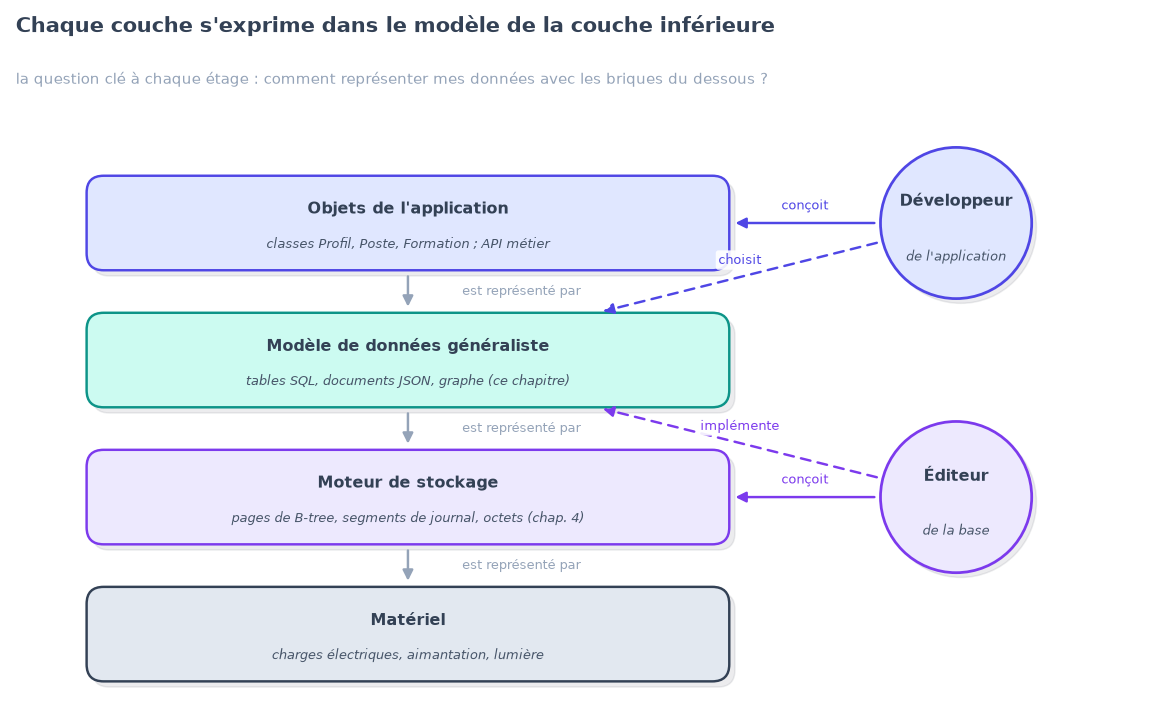

In [2]:
d = Diagram(12, 6.4, title="Chaque couche s'exprime dans le modèle de la couche inférieure",
            subtitle="la question clé à chaque étage : comment représenter mes données avec les briques du dessous ?")
layers = [
    ("app", "Objets de l'application", "classes Profil, Poste, Formation ; API métier", INDIGO),
    ("gen", "Modèle de données généraliste", "tables SQL, documents JSON, graphe (ce chapitre)", TEAL),
    ("eng", "Moteur de stockage", "pages de B-tree, segments de journal, octets (chap. 4)", VIOLET),
    ("hw", "Matériel", "charges électriques, aimantation, lumière", SLATE),
]
for i, (name, txt, sub, col) in enumerate(layers):
    d.box(name, 4.2, 5.1 - 1.45 * i, txt, sub=sub, color=col, w=6.8, h=1.0)
for (a, *_), (b, *_) in zip(layers, layers[1:]):
    d.arrow(a, b, "est représenté par", color=GRAY, label_offset=(1.2, 0))
d.box("dev", 10.0, 5.1, "Développeur", sub="de l'application", kind="user", w=1.6, color=INDIGO)
d.box("ven", 10.0, 2.2, "Éditeur", sub="de la base", kind="user", w=1.6, color=VIOLET)
d.arrow("dev", "app", "conçoit", color=INDIGO)
d.arrow("dev", "gen", "choisit", color=INDIGO, style="dashed")
d.arrow("ven", "gen", "implémente", color=VIOLET, style="dashed")
d.arrow("ven", "eng", "conçoit", color=VIOLET)
d.show()

Le choix du modèle généraliste (couche 2) est le plus lourd de conséquences pour le
développeur : certaines données et certaines requêtes s'expriment naturellement dans un
modèle et maladroitement dans un autre. Le chapitre compare donc les modèles
relationnel, document et graphe, puis l'event sourcing et les DataFrames, ainsi
que leurs langages de requête.

> **À retenir.** Une application empile des modèles de données ; chacun masque la
> complexité de la couche inférieure. Le modèle généraliste choisi (tables, documents,
> graphe) détermine ce qui sera simple ou difficile à exprimer.

## 2. Un demi-siècle de modèles concurrents (section *Relational Versus Document Models*)

Le **modèle relationnel** est proposé par Edgar Codd en 1970 : les données sont des
**relations** (les tables de SQL), ensembles non ordonnés de **n-uplets** (les lignes).
Proposition théorique au départ, dont beaucoup doutaient qu'on sache l'implémenter
efficacement, il s'impose au milieu des années 1980 avec les SGBD relationnels et SQL.

Chaque décennie lui a pourtant opposé un challenger : modèles **hiérarchique** (IMS
d'IBM) et **réseau** (CODASYL) dans les années 1970, bases **objet** à la fin des années
1980, bases **XML** au début des années 2000, puis **NoSQL** à partir de 2009. Aucun n'a
détrôné SQL, qui a fini par absorber leurs idées (types XML, puis JSON).

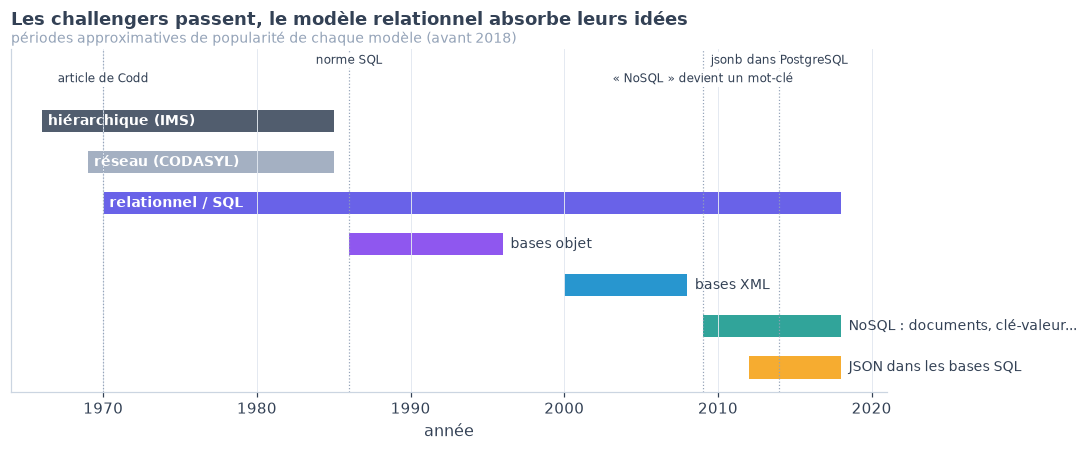

In [3]:
eras = [  # (modèle, début, fin de la période de « battage », couleur)
    ("hiérarchique (IMS)", 1966, 1985, SLATE),
    ("réseau (CODASYL)", 1969, 1985, GRAY),
    ("relationnel / SQL", 1970, 2018, INDIGO),
    ("bases objet", 1986, 1996, VIOLET),
    ("bases XML", 2000, 2008, SKY),
    ("NoSQL : documents, clé-valeur...", 2009, 2018, TEAL),
    ("JSON dans les bases SQL", 2012, 2018, AMBER),
]
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (name, a, b, col) in enumerate(eras):
    ax.barh(i, b - a, left=a, color=col, alpha=0.85, height=0.55)
    if b - a > 14:
        ax.text(a + 0.4, i, name, va="center", ha="left", fontsize=9, color="white", fontweight="bold")
    else:
        ax.text(b + 0.5, i, name, va="center", ha="left", fontsize=9, color=SLATE)
marks = [(1970, "article de Codd"), (1986, "norme SQL"), (2009, "« NoSQL » devient un mot-clé"),
         (2014, "jsonb dans PostgreSQL")]
for k, (yr, txt) in enumerate(marks):
    ax.axvline(yr, color=GRAY, lw=0.8, ls=":")
    ax.text(yr, -0.95 - 0.45 * (k % 2), txt, fontsize=8, color=SLATE, ha="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.set_yticks([]); ax.set_xlim(1964, 2021); ax.set_ylim(-1.75, len(eras) - 0.4)
ax.invert_yaxis()
ax.set_xlabel("année")
ax.set_title("Les challengers passent, le modèle relationnel absorbe leurs idées")
subtitle(ax, "périodes approximatives de popularité de chaque modèle (avant 2018)")
plt.tight_layout(); plt.show()

Dans les années 2010, « NoSQL » désignait moins une technologie qu'un faisceau d'idées :
nouveaux modèles de données, schémas souples, scalabilité, licences libres. Les bases
dites « NewSQL » ont ensuite cherché à marier cette scalabilité au modèle et aux
transactions des bases relationnelles. Ces deux étiquettes se sont effacées à mesure que
leurs principes se diffusaient ; l'héritage le plus durable de NoSQL est la popularité
du **modèle document**, presque toujours en JSON.

Le duel qui nous intéresse oppose donc les **tables** et les **documents JSON**. On
reproche aux tables un schéma rigide, on prête aux documents de la souplesse ; la suite
du chapitre examine ces arguments un par un, chiffres à l'appui.

> **À retenir.** Le modèle relationnel domine depuis les années 1980. Ses challengers
> (hiérarchique, réseau, objet, XML, NoSQL) n'ont pas pris sa place, mais ont laissé des
> idées que SQL a absorbées ; l'héritage principal de NoSQL est le modèle document.

## 3. Le décalage objet-relationnel (section *The Object-Relational Mismatch*)

**Le problème.** Le code applicatif manipule des **objets** imbriqués ; une base
relationnelle stocke des **lignes plates** dans des tables. Il faut une couche de
traduction entre les deux, et ce désaccord porte un nom emprunté à l'électronique :
l'*impedance mismatch*. Deux circuits branchés l'un sur l'autre ne transfèrent bien
l'énergie que si leurs impédances concordent ; ici, ce sont deux façons de voir les
données qui concordent mal.

Prenons l'exemple du livre : un **CV** de réseau professionnel. Voici d'abord sa forme
« naturelle » en Python, avec des objets imbriqués.

In [4]:
@dataclass
class Poste:
    job_title: str
    organization: str
    start: int
    end: int | None = None

@dataclass
class Formation:
    school_name: str
    start: int
    end: int

@dataclass
class Profil:
    user_id: int
    first_name: str
    last_name: str
    headline: str
    region_id: str
    positions: list = field(default_factory=list)
    education: list = field(default_factory=list)
    contact_info: dict = field(default_factory=dict)

ines = Profil(42, "Inès", "Martin", "Architecte de données chez Datanet", "fr:69",
              positions=[Poste("Architecte de données", "Datanet", 2014),
                         Poste("Ingénieure logiciel", "Novasoft", 2009, 2014)],
              education=[Formation("INSA Lyon", 2004, 2009)],
              contact_info={"blog": "https://ines.example", "github": "https://github.example/ines"})
ines

Profil(user_id=42, first_name='Inès', last_name='Martin', headline='Architecte de données chez Datanet', region_id='fr:69', positions=[Poste(job_title='Architecte de données', organization='Datanet', start=2014, end=None), Poste(job_title='Ingénieure logiciel', organization='Novasoft', start=2009, end=2014)], education=[Formation(school_name='INSA Lyon', start=2004, end=2009)], contact_info={'blog': 'https://ines.example', 'github': 'https://github.example/ines'})

Dans un **schéma relationnel**, chaque liste devient une table séparée qui pointe vers
`users` par une **clé étrangère** `user_id` : c'est la représentation classique d'une
relation **un-à-plusieurs** (un profil a plusieurs postes, chaque poste appartient à un
seul profil). Les champs uniques (prénom, nom, titre) restent des colonnes de `users`.

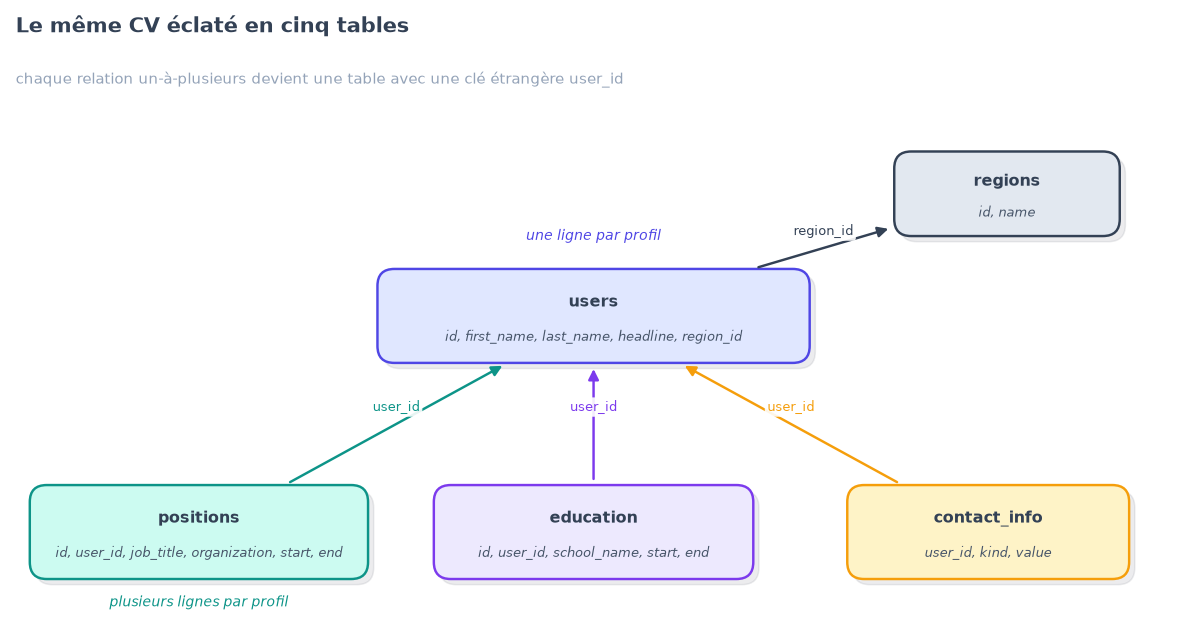

In [5]:
d = Diagram(12.5, 5.6, title="Le même CV éclaté en cinq tables",
            subtitle="chaque relation un-à-plusieurs devient une table avec une clé étrangère user_id")
d.box("users", 6.2, 3.3, "users", sub="id, first_name, last_name, headline, region_id", color=INDIGO, w=4.6, h=1.0)
d.box("pos", 2.0, 1.0, "positions", sub="id, user_id, job_title, organization, start, end", color=TEAL, w=3.6, h=1.0)
d.box("edu", 6.2, 1.0, "education", sub="id, user_id, school_name, start, end", color=VIOLET, w=3.4, h=1.0)
d.box("con", 10.4, 1.0, "contact_info", sub="user_id, kind, value", color=AMBER, w=3.0, h=1.0)
d.box("reg", 10.6, 4.6, "regions", sub="id, name", color=SLATE, w=2.4, h=0.9)
d.arrow("pos", "users", "user_id", color=TEAL)
d.arrow("edu", "users", "user_id", color=VIOLET)
d.arrow("con", "users", "user_id", color=AMBER)
d.arrow("users", "reg", "region_id", color=SLATE)
d.note(6.2, 4.15, "une ligne par profil", color=INDIGO)
d.note(2.0, 0.25, "plusieurs lignes par profil", color=TEAL)
d.show()

La **représentation document** garde l'arbre tel quel : un seul objet JSON contient les
listes de postes et de formations, et le dictionnaire des coordonnées. Elle est
directement sérialisable depuis nos objets Python :

In [6]:
from dataclasses import asdict
doc_ines = asdict(ines)
print(json.dumps(doc_ines, ensure_ascii=False, indent=2))

{
  "user_id": 42,
  "first_name": "Inès",
  "last_name": "Martin",
  "headline": "Architecte de données chez Datanet",
  "region_id": "fr:69",
  "positions": [
    {
      "job_title": "Architecte de données",
      "organization": "Datanet",
      "start": 2014,
      "end": null
    },
    {
      "job_title": "Ingénieure logiciel",
      "organization": "Novasoft",
      "start": 2009,
      "end": 2014
    }
  ],
  "education": [
    {
      "school_name": "INSA Lyon",
      "start": 2004,
      "end": 2009
    }
  ],
  "contact_info": {
    "blog": "https://ines.example",
    "github": "https://github.example/ines"
  }
}


Les relations un-à-plusieurs du profil dessinent un **arbre** : la racine (le profil),
des branches (les listes), des feuilles (les champs). Le document JSON rend cet arbre
explicite, quand le schéma relationnel le disperse dans plusieurs tables qu'il faudra
recoller. Dessinons cet arbre à partir du document lui-même.

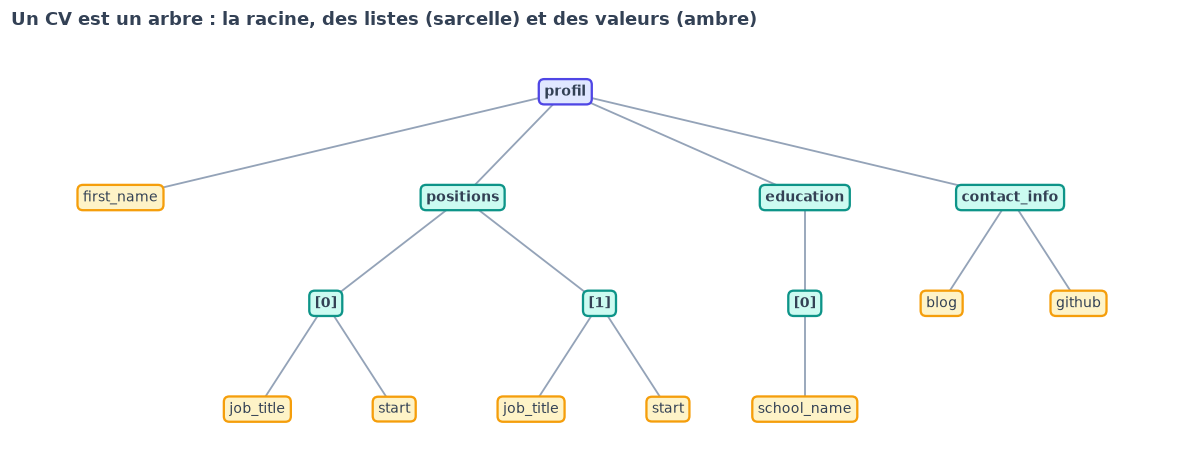

In [7]:
def tree_layout(doc, name="profil"):
    """Positions (x, profondeur) des nœuds d'un document JSON : feuilles espacées régulièrement."""
    nodes, edges, leaves = [], [], [0]
    def visit(key, val, depth, parent):
        idx = len(nodes)
        nodes.append([key, depth, None, isinstance(val, (dict, list))])
        if parent is not None:
            edges.append((parent, idx))
        children = list(val.items()) if isinstance(val, dict) else (
            [(f"[{i}]", v) for i, v in enumerate(val)] if isinstance(val, list) else [])
        if not children:
            nodes[idx][2] = leaves[0]; leaves[0] += 1
        else:
            xs = [visit(k, v, depth + 1, idx) for k, v in children]
            nodes[idx][2] = (min(xs) + max(xs)) / 2
        return nodes[idx][2]
    visit(name, doc, 0, None)
    return nodes, edges

small = {k: doc_ines[k] for k in ["first_name", "positions", "education", "contact_info"]}
small["positions"] = [{"job_title": p["job_title"][:12] + ".", "start": p["start"]} for p in small["positions"]]
small["education"] = [{"school_name": "INSA Lyon"}]
nodes, edges = tree_layout(small)
fig, ax = plt.subplots(figsize=(11, 4.4))
for a, b in edges:
    ax.plot([nodes[a][2], nodes[b][2]], [-nodes[a][1], -nodes[b][1]], color=GRAY, lw=1.2, zorder=1)
for key, depth, x, inner in nodes:
    col = INDIGO if depth == 0 else (TEAL if inner else AMBER)
    ax.text(x, -depth, key, ha="center", va="center", fontsize=9, color=SLATE, zorder=3,
            fontweight="bold" if inner else "normal",
            bbox=dict(boxstyle="round,pad=0.4", fc=LIGHT[col], ec=col, lw=1.5))
ax.set_axis_off(); ax.set_ylim(-3.5, 0.4); ax.set_xlim(-0.8, max(n[2] for n in nodes) + 0.8)
ax.set_title("Un CV est un arbre : la racine, des listes (sarcelle) et des valeurs (ambre)")
plt.tight_layout(); plt.show()

> **À retenir.** Le décalage objet-relationnel vient de ce que les objets de
> l'application sont imbriqués alors que les tables sont plates. Pour des données en
> forme d'**arbre de relations un-à-plusieurs**, comme un CV, le document JSON colle à la
> structure de l'application ; le schéma relationnel l'éclate en plusieurs tables.

## 4. Recomposer un CV : plusieurs requêtes, une jointure ou un document ?

Pour afficher un profil complet à partir du schéma relationnel, deux options : **une
requête par table** (quatre requêtes sur `users`, `positions`, `education`,
`contact_info`) ou **une jointure multiple** qui ramène tout en une fois. Avec le
modèle document, une seule lecture suffit. Comparons les trois sur un jeu de 5 000
profils synthétiques (`dm.make_profiles`), rangés dans les deux formes sur SQLite.

In [8]:
orgs = dm.make_orgs(200, seed=0)
profiles = dm.make_profiles(5_000, seed=0, orgs=orgs)
con = sqlite3.connect(":memory:")
dm.create_relational(con, profiles, orgs)
dm.create_documents(con, profiles)
cc = dm.CountingConnection(con)

lignes = {t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
          for t in ["users", "positions", "education", "contact_info", "profiles"]}
pd.DataFrame({"table": list(lignes), "lignes": list(lignes.values())})

,table,lignes
0,users,5000
1,positions,17284
2,education,7474
3,contact_info,7492
4,profiles,5000


Les trois méthodes de lecture (`get_profile_multi`, `get_profile_join`,
`get_profile_doc`) renvoient exactement le même dictionnaire ; vérifions-le, et comptons
pour chacune le nombre de requêtes et de lignes reçues.

In [9]:
rows = []
for uid in rng.choice(np.arange(1, 5001), 400, replace=False):
    uid = int(uid)
    res = []
    for meth, f in [("4 requêtes", dm.get_profile_multi), ("1 jointure multiple", dm.get_profile_join),
                    ("1 document", dm.get_profile_doc)]:
        cc.reset()
        res.append(f(cc, uid))
        rows.append({"méthode": meth, "uid": uid, "requêtes": cc.queries, "lignes": cc.rows})
    assert res[0] == res[1] == res[2] == profiles[uid - 1]
mesures = pd.DataFrame(rows)
mesures.groupby("méthode", sort=False)[["requêtes", "lignes"]].agg(["mean", "max"])

requêtes      lignes    
                        mean max    mean max
méthode                                     
4 requêtes               4.0   4   7.452  13
1 jointure multiple      1.0   1  10.658  54
1 document               1.0   1   1.000   1

La jointure multiple est séduisante (une seule requête), mais elle a un défaut caché :
les trois listes étant **indépendantes**, la jointure renvoie leur **produit
cartésien**. Un profil de 6 postes, 3 formations et 3 coordonnées produit
$6 \times 3 \times 3 = 54$ lignes pour 13 éléments utiles (l'en-tête et 12 éléments de
listes), qu'il faut ensuite
dédoublonner côté client. C'est la « jointure multiple désordonnée » que le livre
évoque.

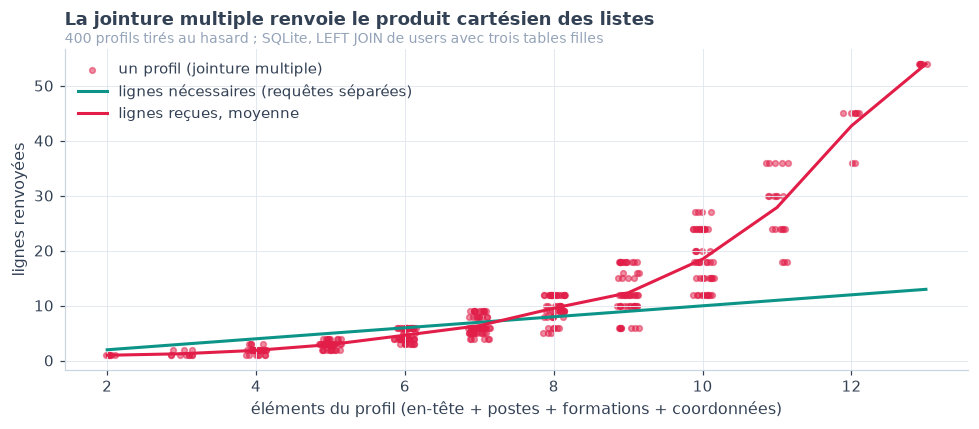

In [10]:
jn = mesures[mesures["méthode"] == "1 jointure multiple"].copy()
utiles = []
for uid in jn.uid:
    p = profiles[uid - 1]
    utiles.append(1 + len(p["positions"]) + len(p["education"]) + len(p["contact_info"]))
jn["éléments utiles"] = utiles
agg = jn.groupby("éléments utiles")["lignes"].agg(["mean", "max"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(jn["éléments utiles"] + rng.uniform(-0.15, 0.15, len(jn)), jn["lignes"], s=14, color=ROSE, alpha=0.5,
           label="un profil (jointure multiple)")
ax.plot(agg.index, agg.index, color=TEAL, lw=2, label="lignes nécessaires (requêtes séparées)")
ax.plot(agg.index, agg["mean"], color=ROSE, lw=2, label="lignes reçues, moyenne")
ax.set_xlabel("éléments du profil (en-tête + postes + formations + coordonnées)")
ax.set_ylabel("lignes renvoyées")
ax.set_title("La jointure multiple renvoie le produit cartésien des listes")
subtitle(ax, "400 profils tirés au hasard ; SQLite, LEFT JOIN de users avec trois tables filles")
ax.legend(); plt.tight_layout(); plt.show()

Côté temps, SQLite s'exécute ici **dans notre processus** : une requête ne coûte que
quelques microsecondes. Une vraie base est **distante**, et chaque requête paie un
aller-retour réseau (de 0,1 ms dans un même centre de données à plusieurs dizaines de
millisecondes entre continents). Le modèle `dm.round_trip_cost` additionne ces
allers-retours et le transfert des lignes ; appliquons-le aux mesures.

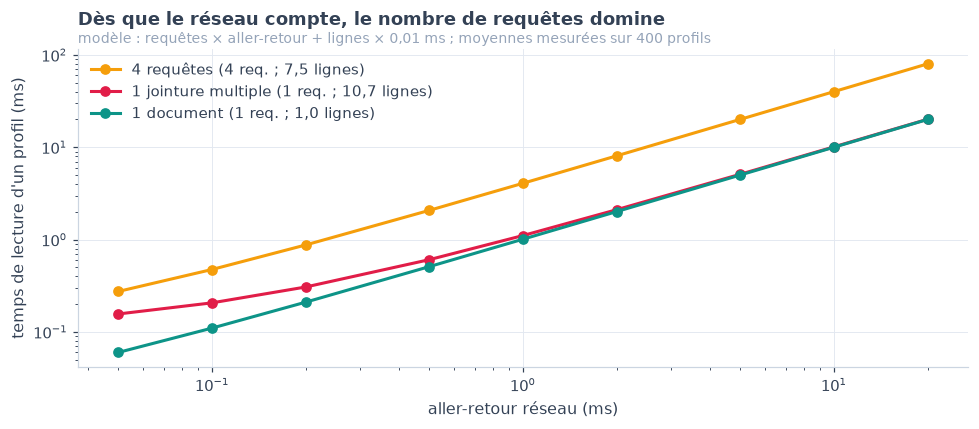

In [11]:
rtts = np.array([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20])
moy = mesures.groupby("méthode", sort=False)[["requêtes", "lignes"]].mean()
fig, ax = plt.subplots(figsize=(9, 4))
for (meth, r), col in zip(moy.iterrows(), [AMBER, ROSE, TEAL]):
    ax.plot(rtts, [dm.round_trip_cost(r["requêtes"], r["lignes"], rtt, per_row_ms=0.01) for rtt in rtts],
            marker="o", color=col, label=f"{meth} ({r['requêtes']:.0f} req. ; " + f"{r['lignes']:.1f}".replace(".", ",") + " lignes)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("aller-retour réseau (ms)"); ax.set_ylabel("temps de lecture d'un profil (ms)")
ax.set_title("Dès que le réseau compte, le nombre de requêtes domine")
subtitle(ax, "modèle : requêtes × aller-retour + lignes × 0,01 ms ; moyennes mesurées sur 400 profils")
ax.legend(); plt.tight_layout(); plt.show()

Les quatre requêtes séparées coûtent quatre allers-retours : quatre fois plus que le
document dès que le réseau dépasse quelques dixièmes de milliseconde. La jointure
multiple n'a qu'un aller-retour mais transporte nettement plus de lignes ; elle reste
compétitive tant que les listes sont courtes. Le document, lui, cumule les deux
avantages : **une requête, une ligne**.

> **À retenir.** Pour recomposer un arbre stocké en tables, on paie soit plusieurs
> allers-retours, soit une jointure multiple qui gonfle en produit cartésien. Le
> document ramène l'arbre entier en une lecture : c'est l'argument de **localité**.

## 5. La localité des données, ses gains et son prix (section *Data locality for reads and writes*)

Un document est stocké comme **une chaîne continue** (JSON, XML, ou une variante binaire
comme le BSON de MongoDB). Si l'application lit souvent le document entier, cette
localité est un gain : une seule recherche dans l'index, des octets contigus. Mais le
gain s'inverse dans deux cas :

- on ne lit qu'**une petite partie** d'un gros document : la base charge quand même le
  tout ;
- on **modifie** un champ : le plus souvent, le document entier est réécrit.

Mesurons le second effet. On modifie le titre (`headline`) d'un profil, d'abord dans la
table `users` (une ligne courte), puis dans des documents de taille croissante, avec la
fonction `json_set` de SQLite qui reconstruit et réécrit le document complet.

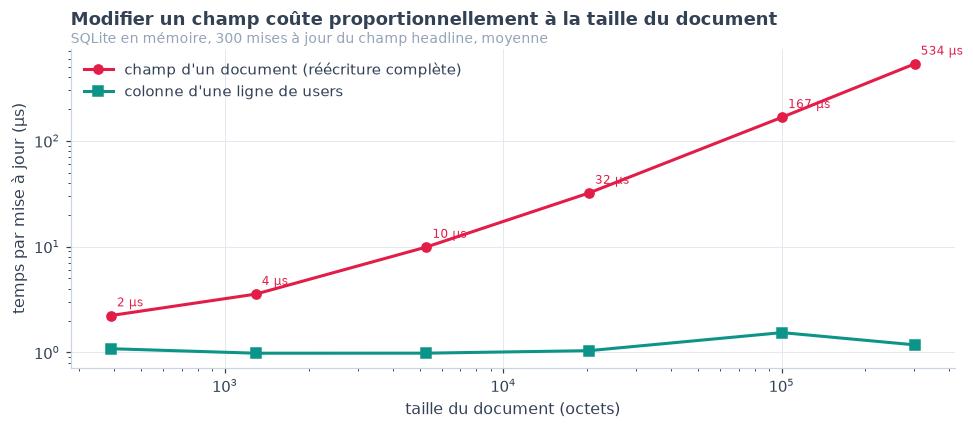

,octets,µs document,µs ligne
0,389,2.2,1.1
1,1289,3.6,1.0
2,5289,9.9,1.0
3,20289,32.1,1.0
4,100289,167.2,1.5
5,300289,534.1,1.2


In [12]:
def time_updates(sql, params_fn, n=300):
    t0 = time.perf_counter()
    for i in range(n):
        con.execute(sql, params_fn(i))
    con.commit()
    return (time.perf_counter() - t0) / n * 1e6

taille, t_doc, t_row = [], [], []
for n_pos in [1, 10, 50, 200, 1000, 3000]:
    big = dict(profiles[0])
    big["positions"] = [dict(profiles[0]["positions"][0], start=1990 + k % 30) for k in range(n_pos)]
    con.execute("DROP TABLE IF EXISTS bigdocs")
    con.execute("CREATE TABLE bigdocs (id INTEGER PRIMARY KEY, doc TEXT)")
    con.executemany("INSERT INTO bigdocs VALUES (?, ?)", [(i, json.dumps(big, ensure_ascii=False)) for i in range(300)])
    taille.append(len(json.dumps(big, ensure_ascii=False).encode()))
    t_doc.append(time_updates("UPDATE bigdocs SET doc = json_set(doc, '$.headline', ?) WHERE id = ?",
                              lambda i: (f"titre {i}", i)))
    t_row.append(time_updates("UPDATE users SET headline = ? WHERE id = ?", lambda i: (f"titre {i}", i + 1)))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(taille, t_doc, marker="o", color=ROSE, label="champ d'un document (réécriture complète)")
ax.plot(taille, t_row, marker="s", color=TEAL, label="colonne d'une ligne de users")
for x, y in zip(taille, t_doc):
    ax.annotate(f"{y:.0f} µs", (x, y), (4, 6), textcoords="offset points", fontsize=8, color=ROSE)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("taille du document (octets)"); ax.set_ylabel("temps par mise à jour (µs)")
ax.set_title("Modifier un champ coûte proportionnellement à la taille du document")
subtitle(ax, "SQLite en mémoire, 300 mises à jour du champ headline, moyenne")
ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"octets": taille, "µs document": t_doc, "µs ligne": t_row}).round(1)

Le coût de la mise à jour d'un document croît à peu près **linéairement** avec sa taille
(au-delà de quelques kilo-octets) ; celui d'une ligne reste constant. Le livre en tire
une règle pratique : garder des documents **assez petits** et éviter les petites mises à
jour fréquentes sur de gros documents.

Lire **une partie** d'un document a le même travers : pour extraire un seul champ,
SQLite doit analyser le texte JSON entier. Comparons la lecture du titre seul dans les
deux représentations, pour des documents de taille croissante.

In [13]:
t_part = []
for n_pos in [1, 10, 50, 200, 1000, 3000]:
    big = dict(profiles[0])
    big["positions"] = [dict(profiles[0]["positions"][0], start=1990 + k % 30) for k in range(n_pos)]
    con.execute("DELETE FROM bigdocs")
    con.executemany("INSERT INTO bigdocs VALUES (?, ?)", [(i, json.dumps(big, ensure_ascii=False)) for i in range(300)])
    t0 = time.perf_counter()
    for i in range(300):
        con.execute("SELECT doc ->> '$.headline' FROM bigdocs WHERE id = ?", (i,)).fetchone()
    t_part.append((time.perf_counter() - t0) / 300 * 1e6)
t0 = time.perf_counter()
for i in range(300):
    con.execute("SELECT headline FROM users WHERE id = ?", (i + 1,)).fetchone()
t_col = (time.perf_counter() - t0) / 300 * 1e6
print("lecture d'un champ (µs) :", ", ".join(f"{o / 1000:.1f} Ko -> {t:.0f}" for o, t in zip(taille, t_part)),
      f"; colonne de users : {t_col:.0f} µs")

lecture d'un champ (µs) : 0.4 Ko -> 2, 1.3 Ko -> 2, 5.3 Ko -> 6, 20.3 Ko -> 19, 100.3 Ko -> 89, 300.3 Ko -> 262 ; colonne de users : 1 µs


La localité n'est d'ailleurs pas l'apanage du modèle document. Le livre cite trois
façons de l'obtenir dans d'autres modèles : Spanner (Google) permet de déclarer qu'une
table est **entrelacée** dans sa table parente (les lignes filles sont rangées avec la
ligne parente) ; Oracle propose des *multi-table index cluster tables* ; et le modèle en
**colonnes larges** de Bigtable (repris par HBase et Accumulo) regroupe les données par
*familles de colonnes* précisément pour maîtriser la localité.

> **À retenir.** La localité d'un document est un gain si on lit souvent **le document
> entier**. Elle devient un coût pour les lectures partielles et surtout pour les
> modifications, qui réécrivent tout le document : il faut garder les documents petits.

## 6. Les ORM et le problème des N+1 requêtes (section *Object-relational mapping*)

Les **ORM** (*object-relational mapping*) comme ActiveRecord ou Hibernate écrivent pour
nous la couche de traduction entre objets et tables. Le livre en dresse un bilan
nuancé :

- **contre** : ils ne masquent jamais complètement la différence entre les deux modèles ;
  ils ne servent que le transactionnel (les équipes analytiques travaillent sur le schéma
  relationnel brut, qui doit donc rester bien conçu) ; ils couvrent mal les systèmes
  non relationnels ; leurs schémas générés sont parfois maladroits ; et ils rendent
  **facile d'écrire des requêtes inefficaces** ;
- **pour** : ils suppriment le code répétitif des cas simples, peuvent mettre en cache
  les résultats et aident à gérer les migrations de schéma.

L'exemple canonique de requête inefficace est le **problème N+1**. Pour afficher N
commentaires et le nom de leur auteur, un ORM paresseux exécute une requête pour la
liste des commentaires, puis **une requête par commentaire** pour charger son auteur
(accès à `comment.author`). Une jointure écrite à la main fait tout en une requête.

In [14]:
con.executescript("""
DROP TABLE IF EXISTS comments;
CREATE TABLE comments (id INTEGER PRIMARY KEY, post_id INTEGER, author_id INTEGER, text TEXT);
CREATE INDEX comments_post ON comments (post_id);
""")
con.executemany("INSERT INTO comments VALUES (?, ?, ?, ?)",
                [(i, i % 50, int(rng.integers(1, 5001)), f"commentaire {i}") for i in range(20_000)])

class LazyComment:
    """Ce qu'un ORM paresseux renvoie : l'auteur n'est chargé qu'au premier accès."""
    def __init__(self, cc, row):
        self.cc, (self.id, self.author_id, self.text) = cc, row
    @property
    def author(self):
        return self.cc.execute("SELECT first_name, last_name FROM users WHERE id = ?", (self.author_id,))[0]

def page_orm(cc, post_id):
    comments = [LazyComment(cc, r) for r in cc.execute(
        "SELECT id, author_id, text FROM comments WHERE post_id = ?", (post_id,))]
    return [(c.text, " ".join(c.author)) for c in comments]       # N accès à .author

def page_join(cc, post_id):
    return [(t, f"{a} {b}") for t, a, b in cc.execute(
        "SELECT c.text, u.first_name, u.last_name FROM comments c JOIN users u ON u.id = c.author_id "
        "WHERE c.post_id = ?", (post_id,))]

cc.reset(); a = page_orm(cc, 7); q_orm = cc.queries
cc.reset(); b = page_join(cc, 7); q_join = cc.queries
assert sorted(a) == sorted(b)
print(f"{len(a)} commentaires : ORM paresseux = {q_orm} requêtes, jointure = {q_join} requête")

400 commentaires : ORM paresseux = 401 requêtes, jointure = 1 requête


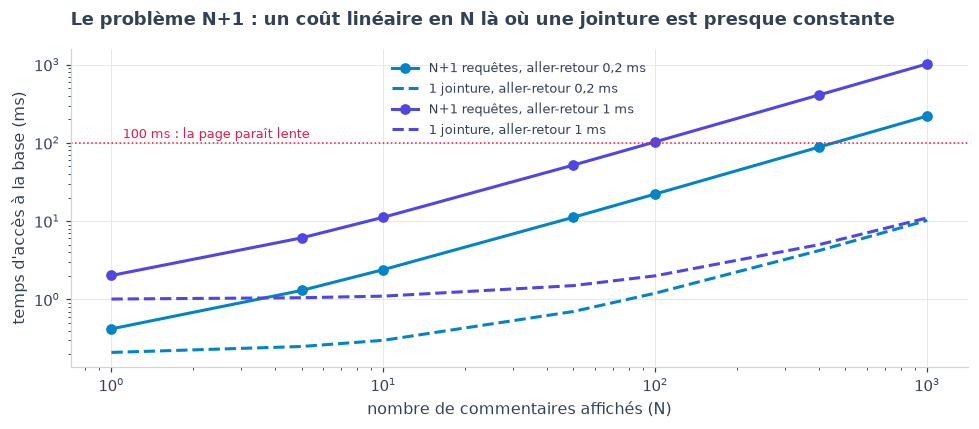

In [15]:
Ns = np.array([1, 5, 10, 50, 100, 400, 1000])
fig, ax = plt.subplots(figsize=(9, 4))
for rtt, col in [(0.2, SKY), (1.0, INDIGO)]:
    ax.plot(Ns, [dm.round_trip_cost(n + 1, 2 * n, rtt, 0.01) for n in Ns], marker="o", color=col,
            label=f"N+1 requêtes, aller-retour {rtt:g} ms".replace(".", ","))
    ax.plot(Ns, [dm.round_trip_cost(1, n, rtt, 0.01) for n in Ns], ls="--", color=col,
            label=f"1 jointure, aller-retour {rtt:g} ms".replace(".", ","))
ax.axhline(100, color=ROSE, lw=1, ls=":"); ax.text(1.1, 115, "100 ms : la page paraît lente", color=ROSE, fontsize=8.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nombre de commentaires affichés (N)"); ax.set_ylabel("temps d'accès à la base (ms)")
ax.set_title("Le problème N+1 : un coût linéaire en N là où une jointure est presque constante")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

Avec 1 000 commentaires et 1 ms d'aller-retour, la page passe une seconde à attendre la
base, contre quelques millisecondes avec la jointure. Le remède consiste à demander à
l'ORM de charger les auteurs **en même temps** que les commentaires (*eager loading* :
une jointure, ou une seconde requête `WHERE id IN (...)`). Nous retrouverons ce problème
avec les résolveurs GraphQL au cours 5.

> **À retenir.** Un ORM réduit le code répétitif mais ne supprime pas le décalage
> objet-relationnel. Son piège le plus courant est la requête N+1 : un accès paresseux
> par objet, donc N allers-retours là où une jointure suffit.

## Synthèse

- Une application **empile des modèles de données** ; le modèle généraliste (tables,
  documents, graphes) conditionne ce qui est simple à exprimer.
- Le **modèle relationnel** domine depuis les années 1980 ; ses challengers successifs
  ont été absorbés. NoSQL a surtout popularisé le **modèle document** en JSON.
- Le **décalage objet-relationnel** : les objets sont imbriqués, les tables plates. Pour
  un **arbre de relations un-à-plusieurs** lu d'un bloc (un CV), le document est plus
  naturel et plus rapide : une lecture au lieu de plusieurs requêtes ou d'une jointure
  en produit cartésien.
- La **localité** a un prix : lectures partielles et mises à jour coûtent la taille du
  document entier. Les ORM masquent mal le décalage et invitent au problème N+1.

Le cours 2 montre la limite du modèle document : dès que les données se référencent
entre elles (plusieurs-à-un, plusieurs-à-plusieurs), il faut des **identifiants** et des
**jointures**. Le stockage physique des documents et des tables est l'objet du chapitre
4, et l'encodage JSON lui-même celui du chapitre 5.